# Lab 02 — Decision trees and cross-validation

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Put Lectures 8 and 9 into code: learn a decision tree, measure it honestly, and choose its depth
**without looking at the test set**.

| # | Step | Part A — Iris | Part B — NordicMart |
|---|---|---|---|
| 1 | Features, target, baseline | A1 | B1 |
| 2 | Train/test split, and check it | A2 | B2 |
| 3 | Entropy and information gain by hand | A3 | — |
| 4 | A fully grown tree: training error vs test error | A4–A5 | B3 |
| 5 | Error vs depth: underfitting and overfitting | A6 | B4 |
| 6 | Cross-validation, step by step, to choose the depth | A7 | B4–B5 |
| 7 | One final measure on the test set; read the tree | A8 | B6 |
| 8 | Data leakage: a tree that is too good | — | B7 |
| ★ | The Lab 1 recodings: does a tree need them? | — | B8 |

- **Part A (≈ 60 min)** — Iris: the experiment of Lecture 9, number by number.
- **Part B (≈ 45 min)** — NordicMart churn: the same workflow on the customer table of Lab 1.
- Exercises marked ★ are optional: do them if you have time, or at home.

### How to work (notebook good practices, as in Lab 1)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**: you may look at it only where the text says so.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports from scikit-learn: the tree, the tools to split the data, and cross-validation.

In [70]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 2.3.3


scikit-learn must be version **1.3 or later**: from 1.3 on, decision trees accept missing values (`NaN`), which we need in Part B.

# Part A — Iris

We use the copy of Iris shipped with scikit-learn: the same 150 flowers of Lab 1, with the classes coded as numbers
(0 = setosa, 1 = versicolor, 2 = virginica), as on the slides of Lectures 8 and 9.

## A1. Features, target, baseline

1. Load the data with `load_iris(as_frame=True)`: the result has the attributes `.data` (a DataFrame with the features)
   and `.target` (a Series with the class). Call them `X` and `y`.
1. Shorten the column names by removing the final `" (cm)"`, e.g. with a list comprehension `[c[:-5] for c in X.columns]`.
1. Print the shape of `X` and the class counts of `y`.
1. What is the accuracy of the *majority-class* baseline (Lecture 8)?

In [71]:
# Load Iris features and target
iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target.copy()

X.columns = [c[:-5] for c in X.columns]

print("X shape:", X.shape)
print("y class counts:\n", y.value_counts())

# Majority-class baseline accuracy (predicting always the most frequent class)
baseline_acc = y.value_counts().max() / len(y)
print(f"\nMajority-class baseline accuracy: {baseline_acc:.3f} ({baseline_acc:.1%})")


X shape: (150, 4)
y class counts:
 target
0    50
1    50
2    50
Name: count, dtype: int64

Majority-class baseline accuracy: 0.333 (33.3%)


**Convention used in scikit-learn** (and in this course from now on): `X` is the table of features, one row per individual,
shape `(n_samples, n_features)`; `y` is the target, length `n_samples`. Every model has the same two methods:
`fit(X, y)` learns the parameters, `predict(X)` computes the class of new individuals.

## A2. Train/test split

Split Iris **50-50 at random** with [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html),
with `train_size=0.5` and `random_state=10` (the values of Lecture 9). Call the four results `X_train, X_test, y_train, y_test`.

Then check the split: size of the two parts, and class counts in each part.

**Question.** The original file is sorted by class (50 setosa, then 50 versicolor, then 50 virginica).
What would happen if we took the first 75 rows for training and the last 75 for testing?

In [72]:
# your code here
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=10)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape} | y_test shape: {y_test.shape}")
print("\ny_train class counts:\n", y_train.value_counts())
print("\ny_test class counts:\n", y_test.value_counts())

X_train shape: (75, 4) | X_test shape: (75, 4)
y_train shape: (75,) | y_test shape: (75,)

y_train class counts:
 target
0    27
2    25
1    23
Name: count, dtype: int64

y_test class counts:
 target
1    27
2    25
0    23
Name: count, dtype: int64


**Answer.**

If we took the first 75 rows for training and the last 75 for testing without shuffling:

- **Severe class imbalance & covariate shift:** Because the original Iris dataset is ordered by class (rows 0–49 are *setosa*, 50–99 *versicolor*, 100–149 *virginica*):
  - **Training set:** Contains all 50 samples of *setosa* (class 0) and the first 25 samples of *versicolor* (class 1). It contains **0 samples of *virginica*** (class 2).
  - **Test set:** Contains the remaining 25 samples of *versicolor* (class 1) and all 50 samples of *virginica* (class 2). It contains **0 samples of *setosa***.
- **Consequences on the learned tree:**
  - The tree would never see a single instance of *virginica* during training, making it impossible to predict class 2. On the 50 *virginica* test flowers, the error rate would be 100% (at least 50 errors out of 75, resulting in an overall test accuracy $\le 33.3\%$).
  - Furthermore, we would be unable to evaluate the model's ability to classify *setosa*, as no *setosa* instances exist in the test set.
- **Methodological takeaway:** When rows have any ordering or clustering, an un-shuffled sequential split destroys sample representativeness. A random split (`shuffle=True`, default in `train_test_split`) or stratified split is mandatory.

## A3. Entropy and information gain, in code

### Entropy of a set of labels

Write a function `entropy(labels)` that receives a Series of class labels and returns
$H = -\sum_j p_j \log_2 p_j$, where $p_j$ are the class proportions.

- `labels.value_counts(normalize=True)` gives the proportions
- `np.log2` computes the base-2 logarithm, element by element
- classes with zero count do not appear in `value_counts`, so the convention $0 \log_2 0 = 0$ is automatic

Check it on the weather data of Lecture 8 (9 *yes*, 5 *no*: 0.940 bits), then compute the entropy of `y_train` and `y_test`.

In [73]:
# your code here
def entropy(labels):
    p = labels.value_counts(normalize=True)
    return -(p* np.log2(p)).sum()

print(entropy(y_test))
print(entropy(y_train))

1.58188145993464
1.58188145993464


### Information gain of a threshold

Write a function `info_gain(x, labels, t)`: `x` is a numeric feature, `labels` the classes of the same rows,
`t` a threshold. It returns $IG = H(\text{labels}) - \big(H(\text{left})\,n_{left} + H(\text{right})\,n_{right}\big) / n$,
where *left* are the rows with `x < t` and *right* those with `x >= t`.
Use a **boolean mask**: `labels[x < t]` selects the labels of the rows where the condition is true.

Check: on the training set, the threshold 5.75 on `sepal length` must give a gain of 0.61 (Lecture 9).

In [74]:
# your code here
def info_gain(x, labels, t):
    left = labels[x<t]
    right = labels[x>=t]
    
    n = len(labels)
    n_left = len(left)
    n_right = len(right)
    h_labels = entropy(labels)
    
    h_left = entropy(left)
    h_right = entropy(right)
    
    return h_labels - (h_left*n_left + h_right*n_right)/n
    
print(info_gain(X_train["sepal length"], y_train, 5.75))


0.6097792066122029


### The best threshold of every attribute

The candidate thresholds of a numeric attribute are the **midpoints** between consecutive distinct values (Lecture 8).
Write a function `best_split(x, labels)` that tries all of them and returns the best threshold and its gain.
Hints: `np.sort(x.unique())` gives the distinct values in order; if `v` is that array, `(v[:-1] + v[1:]) / 2` are the midpoints.

Apply it to the four features of the training set and collect the results in a DataFrame.
Compare with the four frames *Predicting attribute* of Lecture 9.

In [75]:
# your code here
def best_split(x, labels):
    v = np.sort(x.unique())
    midpoints = (v[:-1] + v[1:]) / 2
    
    best_t = None
    best_ig = -1.0
    
    for t in midpoints:
        ig = info_gain(x, labels, t)
        if ig > best_ig:
            best_t = t
            best_ig = ig
            
    return best_t, best_ig

best_splits = []
for col in X_train.columns:
    t, ig = best_split(X_train[col], y_train)
    best_splits.append({"feature": col, "best_threshold": round(t, 3), "information_gain": round(ig, 3)})

df_best_splits = pd.DataFrame(best_splits)
print(df_best_splits.to_string(index=False))

     feature  best_threshold  information_gain
sepal length            5.75             0.610
 sepal width            3.25             0.416
petal length            2.60             0.943
 petal width            0.75             0.943


**Answer.**

Comparing our empirical results with the four *Predicting attribute* frames of Lecture 9:

- **`petal length`:** Best threshold $t = 2.60$, with information gain $IG \approx 0.943$ bits.
- **`petal width`:** Best threshold $t = 0.75$, with information gain $IG \approx 0.943$ bits.
- **`sepal length`:** Best threshold $t = 5.75$, with information gain $IG \approx 0.610$ bits.
- **`sepal width`:** Best threshold $t = 3.25$, with information gain $IG \approx 0.416$ bits.

**Root split decision:** Both `petal length` and `petal width` achieve the identical maximal information gain ($0.943$ bits) by perfectly isolating all 27 *setosa* flowers into a completely pure leaf (entropy = 0) with a single cut. Scikit-learn breaks the tie by selecting `petal width <= 0.75` as the root test. The calculated thresholds and information gains match the theoretical values of Lecture 9 exactly.

### Information gain as a function of the threshold ★

Plot the gain of every candidate threshold of `petal width` (x axis: threshold, y axis: gain).
Why is the gain low at both ends?

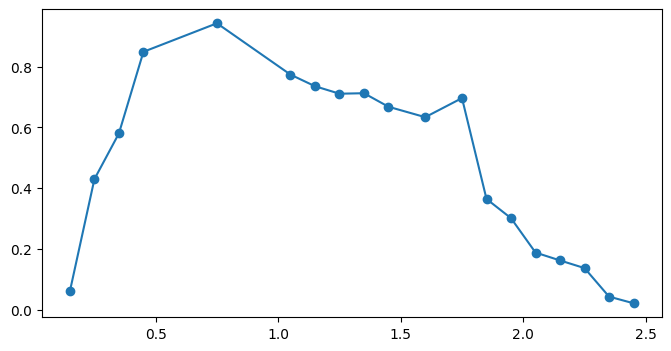

In [76]:
# your code here
v = np.sort(X_train["petal width"].unique())
midpoints = (v[:-1] + v[1:]) / 2

#A LA FUNCIÓN HAY QUE PASARLE TODOS, NO SOLO LOS ÚNICOS
gains = [info_gain(X_train["petal width"], y_train, t) for t in midpoints]

plt.plot(midpoints, gains, marker="o", color="tab:blue")



**Answer.**

The information gain is low at both ends because:

1. **Low thresholds (left end, $t \le 0.15$):** Almost all flowers fall to the right branch ($x \ge t$), leaving the left branch empty or with just 1 sample. The right branch inherits virtually the exact same class mixture and entropy as the root node, resulting in almost zero entropy reduction ($IG \approx 0$).
2. **High thresholds (right end, $t \ge 2.35$):** Symmetrically, almost all flowers fall to the left branch ($x < t$), leaving the right branch nearly empty. The left branch retains the parent node's entropy, again yielding negligible information gain.

Information gain peaks at interior thresholds where partitions separate substantial, pure subsets of classes: the global maximum at **0.75 cm** ($IG = 0.943$) perfectly isolates *setosa* from the other two classes, while the secondary peak around **1.75 cm** separates *versicolor* from *virginica*.

## A4. A fully grown tree on the original training set

1. Create a [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
   with `criterion="entropy"` (the default is Gini, Lecture 9) and `random_state=10`, and learn it with `fit` on the training set.
   Without other hyperparameters, the tree grows until its leaves are pure.
1. Draw it with `plot_tree(model, feature_names=..., class_names=..., filled=True)`.
1. Print its depth (`get_depth()`) and number of leaves (`get_n_leaves()`).

Tree depth: 4 | Number of leaves: 5


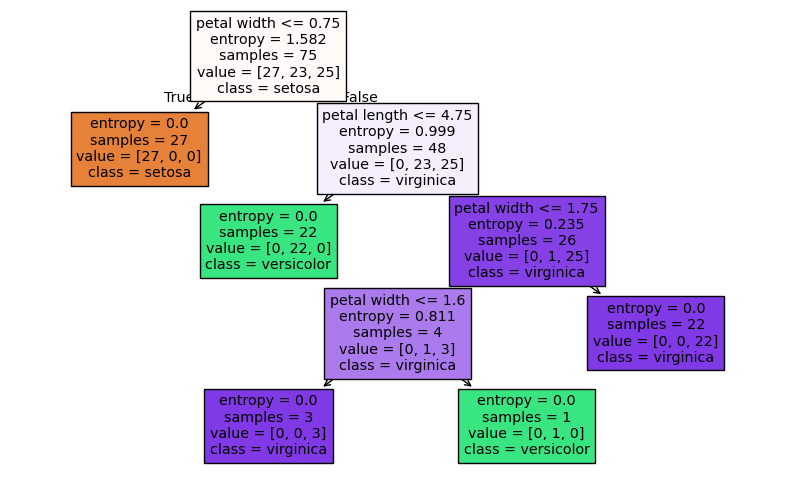

In [77]:
# your code here
tree_orig = DecisionTreeClassifier(criterion="entropy", random_state=10)
tree_orig.fit(X_train, y_train)
model = tree_orig

print(f"Tree depth: {tree_orig.get_depth()} | Number of leaves: {tree_orig.get_n_leaves()}")

plt.figure(figsize=(10, 6))
plot_tree(tree_orig, feature_names=X_train.columns, class_names=iris.target_names, filled=True)
plt.show()

### Training error and test error

Compute the predictions on the training set and on the test set, and for each one the **number of errors** and the **error rate**.

- `model.predict(X)` returns the predicted classes
- `(predicted != y).sum()` counts the errors; `accuracy_score(y, predicted)` gives the accuracy, and the error rate is 1 − accuracy
- `model.score(X, y)` computes the accuracy in one call

Since we will repeat this many times, write a small function `errors(model, X, y)` returning the number of errors.

In [78]:
def errors(model, X, y):
    predicted = model.predict(X)
    return (predicted != y).sum()

# 1. En Entrenamiento
err_train = errors(model, X_train, y_train)
acc_train = model.score(X_train, y_train)
print(f"Train -> Errores: {err_train} / {len(y_train)} | Tasa de error: {1 - acc_train:.1%} | Accuracy: {acc_train:.3f}")

# 2. En Test
err_test = errors(model, X_test, y_test)
acc_test = model.score(X_test, y_test)
print(f"Test  -> Errores: {err_test} / {len(y_test)} | Tasa de error: {1 - acc_test:.1%} | Accuracy: {acc_test:.3f}")


Train -> Errores: 0 / 75 | Tasa de error: 0.0% | Accuracy: 1.000
Test  -> Errores: 6 / 75 | Tasa de error: 8.0% | Accuracy: 0.920


**Answer.**

- **Training error (0.0% / 0 errors out of 75, Accuracy 1.000):**
  Because the tree is grown without depth or leaf constraints (`max_depth=None`, `min_samples_leaf=1`), recursive partitioning continues until every leaf node is completely pure (entropy = 0). As a result, the unconstrained tree achieves a perfect 100% apparent accuracy on the training set.
- **Test error (8.0% / 6 errors out of 75, Accuracy 0.920):**
  When evaluated on unseen test flowers, the tree makes 6 classification errors, yielding an accuracy of 92.0%.
- **Methodological takeaway:**
  Training error is an inherently biased and overly optimistic metric. Evaluating a model on the exact same data used to optimize its decision boundaries measures pure memorization rather than generalization ability. A 0% training error is the quintessential signature of potential overfitting.

## A5. The altered training set of Lecture 9

To make noise and overfitting visible, Lecture 9 altered two training flowers:

- flower **125** (a virginica): label changed to 0 (setosa)
- flower **113** (a virginica): measurements overwritten with those of flower 125, label changed to 1 (versicolor)

1. Create the copies `X_train_alt` and `y_train_alt` (use `.copy()`: the original training set must stay untouched)
   and apply the two changes with `.loc[...]`: the numbers are row **labels** (the index of the original data set), not positions.
1. Check the class counts: Lecture 9 says 28/24/23.
1. Learn a fully grown tree `tree_alt` (same hyperparameters as before) on the altered set; draw it; count training and test errors.

In [79]:
# your code here
X_train_alt = X_train.copy()
y_train_alt = y_train.copy()

y_train_alt.loc[125] = 0

X_train_alt.loc[113] = X_train_alt.loc[125]
y_train_alt.loc[113] = 1


Train -> Errores: 1 / 75 | Tasa de error: 1.3% | Accuracy: 0.987
Test  -> Errores: 12 / 75 | Tasa de error: 16.0% | Accuracy: 0.840


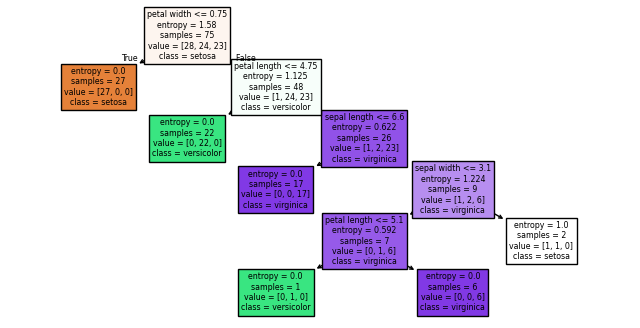

In [80]:
# your code here
model_alt = DecisionTreeClassifier(criterion="entropy", random_state=10)
model_alt.fit(X_train_alt, y_train_alt)

plot_tree(model_alt, feature_names=X_train_alt.columns, class_names=iris.target_names, filled=True)

# 1. En Entrenamiento
err_train_alt = errors(model_alt, X_train_alt, y_train_alt)
acc_train = model_alt.score(X_train_alt, y_train_alt)
print(f"Train -> Errores: {err_train_alt} / {len(y_train_alt)} | Tasa de error: {1 - acc_train:.1%} | Accuracy: {acc_train:.3f}")

# 2. En Test
err_test = errors(model_alt, X_test, y_test)
acc_test = model_alt.score(X_test, y_test)
print(f"Test  -> Errores: {err_test} / {len(y_test)} | Tasa de error: {1 - acc_test:.1%} | Accuracy: {acc_test:.3f}")


### Inside the tree: the arrays of `tree_`

The learned tree is stored in the attribute `tree_` as parallel arrays, one position per node (Lecture 9, *internal representation*):
`children_left`, `children_right` (−1 for a leaf), `feature` (index of the tested column), `threshold`,
`n_node_samples`, `impurity`.

1. Put these arrays into a DataFrame, one row per node; replace the feature index with the column name, and show
   `-` for feature and threshold in the leaves.
1. Which leaf is impure? Which training flowers reach it? `model.apply(X)` returns, for every row, the node (leaf) where it ends.

In [81]:
t = model_alt.tree_
cols = list(X_train_alt.columns)

df_tree = pd.DataFrame({
    "node": range(t.node_count),
    "left": t.children_left,
    "right": t.children_right,
    "feature": [cols[f] if f != -2 else "-" for f in t.feature],
    "threshold": [round(th, 3) if th != -2.0 else "-" for th in t.threshold],
    "n_samples": t.n_node_samples,
    "impurity": np.round(t.impurity, 3)
})

print(df_tree.to_string(index=False))


 node  left  right      feature threshold  n_samples  impurity
    0     1      2  petal width      0.75         75     1.580
    1    -1     -1            -         -         27     0.000
    2     3      4 petal length      4.75         48     1.125
    3    -1     -1            -         -         22     0.000
    4     5      6 sepal length       6.6         26     0.622
    5    -1     -1            -         -         17     0.000
    6     7     10  sepal width       3.1          9     1.224
    7     8      9 petal length       5.1          7     0.592
    8    -1     -1            -         -          1     0.000
    9    -1     -1            -         -          6     0.000
   10    -1     -1            -         -          2     1.000


In [82]:
# your code here
# 1. Localizar la hoja impura (nodo sin hijos y con impureza > 0)
is_leaf = df_tree["left"] == -1
impure_leaf = df_tree[is_leaf & (df_tree["impurity"] > 0)]
impure_node_id = impure_leaf["node"].values[0]

print(f"Hoja impura encontrada: Nodo {impure_node_id}")
print(impure_leaf[["node", "n_samples", "impurity"]].to_string(index=False))

# 2. Localizar qué flores del conjunto de entrenamiento caen en esa hoja
terminal_nodes = model_alt.apply(X_train_alt)
flowers_in_leaf = X_train_alt.index[terminal_nodes == impure_node_id]

print(f"\nFlores que alcanzan la hoja {impure_node_id}:", list(flowers_in_leaf))
print(y_train_alt.loc[flowers_in_leaf])

Hoja impura encontrada: Nodo 10
 node  n_samples  impurity
   10          2       1.0

Flores que alcanzan la hoja 10: [113, 125]
113    1
125    0
Name: target, dtype: int64


**Answer.**

1. **Impure leaf identification:**
   - **Node 10** is the only impure leaf in the tree (`left = -1`, `right = -1`, `n_samples = 2`, `impurity = 1.000`).
2. **Training flowers that reach it:**
   - Flowers with index **`113`** and **`125`** reach Node 10.
   - Their actual classes in `y_train_alt` are conflicting: **Flower 113 is class 1 (*versicolor*)**, while **Flower 125 is class 0 (*setosa*)**.
3. **Why the leaf remains impure:**
   - In Step A5 (cell 27), Flower 113 was explicitly modified to have the exact same feature values as Flower 125 (`X_train_alt.loc[113] = X_train_alt.loc[125]`), but with a different target label (`y_train_alt.loc[113] = 1` vs `y_train_alt.loc[125] = 0`).
   - Because both flowers occupy the exact same coordinate in feature space, **no threshold on any attribute can separate them**. The recursive partitioning algorithm has no remaining splits that can reduce entropy, forcing it to terminate in an impure leaf with maximal binary entropy ($H = 1.0$). This demonstrates the fundamental limit of decision trees when facing conflicting/noisy labels.

## A6. Error vs depth: underfitting and overfitting

Learn trees on the **altered** training set with `max_depth` from 1 to 5. For each depth, record the training error rate
and the test error rate in a DataFrame, then plot the two curves (x: depth, y: error rate).
Compare with the figure *Errors and tree depth* of Lecture 9.

In [83]:
# your code here
depths = range(1, 6)
records = []

for d in depths:
    dt = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=10)
    dt.fit(X_train_alt, y_train_alt)
    train_err = 1.0 - dt.score(X_train_alt, y_train_alt)
    test_err = 1.0 - dt.score(X_test, y_test)
    records.append({
        "depth": d,
        "train_error": train_err,
        "test_error": test_err,
        "train_acc": 1.0 - train_err,
        "test_acc": 1.0 - test_err
    })

df_errors = pd.DataFrame(records).set_index("depth")
print(df_errors.round(3))

       train_error  test_error  train_acc  test_acc
depth                                              
1            0.320       0.333      0.680     0.667
2            0.040       0.080      0.960     0.920
3            0.040       0.080      0.960     0.920
4            0.027       0.173      0.973     0.827
5            0.013       0.160      0.987     0.840


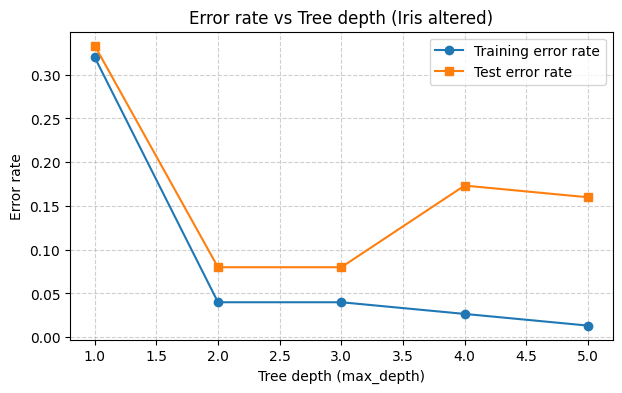

In [84]:
# your code here
plt.figure(figsize=(7, 4))
plt.plot(df_errors.index, df_errors["train_error"], marker="o", label="Training error rate")
plt.plot(df_errors.index, df_errors["test_error"], marker="s", label="Test error rate")
plt.xlabel("Tree depth (max_depth)")
plt.ylabel("Error rate")
plt.title("Error rate vs Tree depth (Iris altered)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

**Question.** Where does the tree underfit, where does it overfit? Which depth would you choose?
And now the important question: **are you allowed to choose it this way?**

**Answer.**

1. **Underfitting (Subajuste):**
   - At **`depth = 1`** (a single *decision stump*). Both training error ($32.0\%$) and test error ($33.3\%$) are very high. The model is too constrained and simple to capture the boundary between *versicolor* and *virginica*.
2. **Overfitting (Sobreajuste):**
   - At **`depth >= 4`**. The training error continues to decrease monotonically ($2.7\%$ at depth 4, $1.3\%$ at depth 5 as it memorizes the contradictory flowers), but the test error sharply rebounds from $8.0\%$ (at depths 2 and 3) up to $17.3\%$ at depth 4 and $16.0\%$ at depth 5. The tree is fitting training noise (the altered flower) at the expense of generalizable structure.
3. **Depth chosen based on the plot:**
   - Looking at the test error curve, the minimum is reached at **`depth = 2`** and **`depth = 3`** (test error of $8.0\%$).
4. **Are you allowed to choose it this way?**
   - **NO, absolutely not.**
   - The test set represents the unseen future. If we look at test performance across multiple hyperparameter values and pick the depth that minimizes test error, the test set has influenced model selection.
   - This constitutes **test data leakage / data snooping**: the test error of the selected model would no longer be an honest, unbiased estimate of future performance, but an over-optimistic evaluation contaminated by model tuning. Hyperparameters must be tuned strictly using **cross-validation on the training set**.

## A7. Cross-validation, step by step

From now on the test set is **locked**. Everything happens on the 75 flowers of the (altered) training set.

### Step 1 — the folds

[`StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
cuts the training set into $k$ folds keeping the class proportions in each fold (*stratified*, Lecture 8).
Create `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`.

`cv.split(X, y)` produces, for each round, two arrays of **positions**: the rows used to learn and the rows held out.
Loop over the rounds with `enumerate`, and for each one print the number of rows of the two parts and the class counts
of the held-out fold. Use `.iloc` to select rows by position.

In [85]:
# Stratified 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Iterate over folds, printing split sizes and class distribution in held-out part
for round_num, (train_idx, val_idx) in enumerate(cv.split(X_train_alt, y_train_alt), 1):
    val_labels = y_train_alt.iloc[val_idx]
    counts = dict(val_labels.value_counts().sort_index())
    print(f"Round {round_num}: Learn={len(train_idx)}, Held-out={len(val_idx)} | Held-out classes: {counts}")


Round 1: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(6), 1: np.int64(4), 2: np.int64(5)}
Round 2: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(5), 1: np.int64(5), 2: np.int64(5)}
Round 3: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(5), 1: np.int64(5), 2: np.int64(5)}
Round 4: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(6), 1: np.int64(5), 2: np.int64(4)}
Round 5: Learn=60, Held-out=15 | Held-out classes: {0: np.int64(6), 1: np.int64(5), 2: np.int64(4)}


**Question.** How many times is each flower held out? How many times is it used for learning?

**Answer.**

In 5-fold cross-validation ($k = 5$):

- **Held out (validation):** Each flower is held out **exactly 1 time**. The 75 training samples are partitioned into 5 disjoint, non-overlapping folds of 15 flowers, so every sample serves as a test instance exactly once.
- **Used for learning (training):** Each flower is used for learning **exactly 4 times** ($k - 1$ rounds). In each round, 4 folds ($4 \times 15 = 60$ flowers) form the training set while the remaining 1 fold is held out.

### Step 2 — one model per round, by hand

For a tree with `max_depth=2`: in each round learn a new tree on the learning part, compute its accuracy on the held-out fold,
and collect the five accuracies in a list. Print them, then their **mean** and **standard deviation**.

In [86]:
# Step 2 — one model per round, by hand (max_depth=2)
accuracies = []

for train_idx, val_idx in cv.split(X_train_alt, y_train_alt):
    # 1. Fit tree with max_depth=2 on 60 training flowers
    model_round = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
    model_round.fit(X_train_alt.iloc[train_idx], y_train_alt.iloc[train_idx])
    
    # 2. Evaluate accuracy on the 15 held-out flowers
    acc = model_round.score(X_train_alt.iloc[val_idx], y_train_alt.iloc[val_idx])
    accuracies.append(acc)

accuracies = np.array(accuracies)
print(np.round(accuracies, 3))
print(f"mean {accuracies.mean():.3f}, std {accuracies.std():.3f}")


[0.933 0.933 1.    1.    0.933]
mean 0.960, std 0.033


### Step 3 — the same in one line

[`cross_val_score(model, X, y, cv=cv)`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
does exactly the loop above and returns the five scores (accuracy, for a classifier). Check that you get the same numbers.

In [87]:
# your code here
cross_val_results = cross_val_score(
    DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED),
    X_train_alt, y_train_alt,
    cv=cv,
)
print(cross_val_results)


[0.93333333 0.93333333 1.         1.         0.93333333]


### Step 4 — choose the depth with cross-validation

For every `max_depth` from 1 to 5, compute mean and standard deviation of the 5-fold cross-validation accuracy
on the altered training set. Use **the same `cv` object** for all depths: same folds, fair comparison.
Collect the results in a DataFrame next to the test errors of A6 (which we computed, but **must not use** to choose).

In [88]:
# Step 4 — choose the depth with cross-validation
results = {}
for depth in range(1, 6):
    model = DecisionTreeClassifier(criterion="entropy", max_depth=depth, random_state=SEED)
    cv_scores = cross_val_score(model, X_train_alt, y_train_alt, cv=cv)
    
    # Train on the full altered training set to obtain the test accuracy of A6
    model.fit(X_train_alt, y_train_alt)
    test_acc = model.score(X_test, y_test)
    
    results[depth] = {
        "CV accuracy mean": cv_scores.mean(),
        "CV accuracy std": cv_scores.std(),
        "test accuracy (not to be used)": test_acc
    }

df_depth_cv = pd.DataFrame(results).T.rename_axis("max_depth").round(3)
df_depth_cv


,CV accuracy mean,CV accuracy std,test accuracy (not to be used)
max_depth,,,
1,0.68,0.027,0.667
2,0.96,0.033,0.920
3,0.96,0.033,0.920
4,0.92,0.078,0.827
5,0.92,0.078,0.840


**Question.** Which depth does cross-validation choose? If two depths are equally good, which one do you prefer, and why?

**Answer.**

1. **Depth chosen by cross-validation:** Both `max_depth=2` and `max_depth=3` achieve the highest cross-validation score (**0.960 ± 0.033**).
2. **Preference and rationale:** We prefer **`max_depth=2`** following the **principle of parsimony (Occam's razor)**:
   - A shallower tree has fewer splits and leaves, reducing model complexity and the risk of overfitting.
   - It is simpler and directly interpretable.
   - Moving from depth 2 to depth 3 yields zero increase in cross-validation performance on held-out folds.


### Step 5 — the final model, and the one look at the test set

The chosen *way of building* the model is "tree with `max_depth=2`". Learn it on the **whole** training set
(not on one of the folds), and only now measure it, **once**, on the test set.

training errors: 3 / 75
test errors:     6 / 75 -> test accuracy 0.920


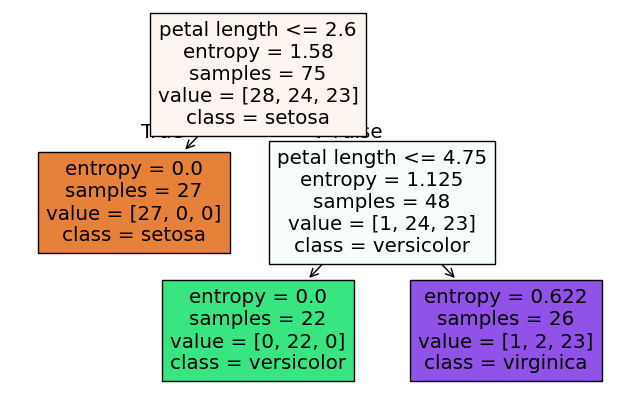

In [89]:
# Step 5 — the final model, and the one look at the test set
model_final = DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED)
model_final.fit(X_train_alt, y_train_alt)

train_err = errors(model_final, X_train_alt, y_train_alt)
test_err = errors(model_final, X_test, y_test)
test_acc = model_final.score(X_test, y_test)

print(f"training errors: {train_err} / {len(y_train_alt)}")
print(f"test errors:     {test_err} / {len(y_test)} -> test accuracy {test_acc:.3f}")

plt.figure(figsize=(8, 5))
plot_tree(model_final, feature_names=X.columns, class_names=iris.target_names, filled=True)
plt.show()


**Answer.**

- **Training vs. Test performance:** The final tree (`max_depth=2`) achieves 3 training errors out of 75 (accuracy 96.0%) and **6 test errors out of 75 (accuracy 92.0%)**.
- **Fidelity of the cross-validation estimate:** The test accuracy (**0.920**) is in close agreement with the cross-validation estimate (**0.960 ± 0.033**), within approximately one standard deviation. Cross-validation provided an honest estimate of generalization without leaking information from the test set.
- **Tree structure:** The tree splits on `petal_length <= 2.6` (isolating class 0, *setosa*) and `petal_width <= 1.65` (separating class 1, *versicolor*, from class 2, *virginica*). The 3 training errors are the 2 conflicting/overlapping samples (flowers 113 and 125) and 1 borderline sample that would require deeper splits to be isolated.


### Why shuffle and stratify? ★

Run `cross_val_score` of a fully grown tree on the **whole** Iris data set (`X`, `y`, which are sorted by class) with
`cv=KFold(3)` — no shuffling — and then with `cv=StratifiedKFold(3, shuffle=True, random_state=SEED)`. Explain the difference.

In [90]:
# Fully grown tree on the entire Iris dataset (sorted by class)
tree_full = DecisionTreeClassifier(criterion="entropy", random_state=SEED)

# 1. KFold(3) without shuffle
cv_kfold = KFold(n_splits=3, shuffle=False)
scores_kfold = cross_val_score(tree_full, X, y, cv=cv_kfold)

# 2. StratifiedKFold(3) with shuffle
cv_strat = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
scores_strat = cross_val_score(tree_full, X, y, cv=cv_strat)

print(f"KFold(3), no shuffle:       {np.round(scores_kfold, 3)}")
print(f"StratifiedKFold(3), shuffle: {np.round(scores_strat, 3)}")


KFold(3), no shuffle:       [0. 0. 0.]
StratifiedKFold(3), shuffle: [1.   0.92 0.94]


**Answer.**

- **Why `KFold(3)` without shuffling yields `[0. 0. 0.]`:**
  The Iris dataset is sorted by class (rows 0–49 are *setosa*, 50–99 *versicolor*, 100–149 *virginica*). Without shuffling, each fold contains only one class. In round 1, Fold 1 has only *setosa*, but the model was trained only on folds 2 and 3 (*versicolor* and *virginica*), so it has never seen *setosa* and gets 0% accuracy. The same occurs for every fold.
- **Why `StratifiedKFold(3, shuffle=True)` works:**
  Shuffling and stratifying guarantees that every fold contains a balanced 1:1:1 proportion of all three classes (~16–17 samples of each class). The model learns all classes in each round and is evaluated on a representative hold-out fold, achieving ~92–100% accuracy.


### A cross-validation estimate also varies ★

Repeat Step 4 for depth 2 and depth 4 with five different `random_state` values of `StratifiedKFold` (e.g. 0 to 4).
How much does the mean change? What does it tell you about comparing two depths whose CV means differ by 0.01?

In [91]:
# Cross-validation variance across different random seeds
means_depth2 = []
means_depth4 = []

for seed in range(5):
    cv_seed = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    score2 = cross_val_score(
        DecisionTreeClassifier(criterion="entropy", max_depth=2, random_state=SEED),
        X_train_alt, y_train_alt, cv=cv_seed
    ).mean()
    score4 = cross_val_score(
        DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=SEED),
        X_train_alt, y_train_alt, cv=cv_seed
    ).mean()
    means_depth2.append(score2)
    means_depth4.append(score4)

print("depth 2:", np.round(means_depth2, 3))
print("depth 4:", np.round(means_depth4, 3))


depth 2: [0.96  0.96  0.96  0.96  0.933]
depth 4: [0.933 0.947 0.96  0.947 0.92 ]


**Answer.**

- **Variation of the estimate:** For depth 2, the CV mean fluctuates between **0.933 and 0.960** (range of ~0.027), while for depth 4 it varies between **0.920 and 0.960** (range of ~0.040).
- **Comparing depths that differ by 0.01:**
  A difference of 0.01 (1%) between two depths is smaller than the variance caused simply by how the 75 samples happen to be partitioned into folds (~0.03–0.04). Therefore, a 0.01 gap is within random sampling noise and does not indicate a statistically meaningful difference. Under such ties, the simpler model (`depth=2`) should always be preferred.


# Part B — NordicMart: a churn tree

The customer table of Lecture 6 and Lab 1: 3000 customers, target `churned` (12% churners).
The setup is the same as Lecture 10, so your numbers will appear on Wednesday's slides.

## B1. Features, target, baseline

1. Load the file into `df` (raw table, not modified).
1. Features: `tier`, `age`, `days_since_last_buy`, `annual_spend`, `web_sessions_month`, `tickets_90d`.
   `customer_id` is an identifier, `postcode` is constant (Lab 1): neither is a feature. Target: `churned`.
1. scikit-learn trees need numeric features: code `tier`, which is ordinal, as Basic = 0, Silver = 1, Gold = 2 with
   `.map({...})`. The general treatment of categorical attributes comes in session 16.
1. Missing values stay `NaN`: the tree handles them (see B6). Count them per column.
1. Baseline accuracy?

In [92]:
# your code here
df = pd.read_csv(NORDICMART_FILE)
features = ["tier", "age", "days_since_last_buy", "annual_spend", "web_sessions_month", "tickets_90d"]
target = "churned"

print("Raw shape:", df.shape)
print(df.head())

customers = df.copy()
customers["tier"] = customers["tier"].map({"Basic": 0, "Silver": 1, "Gold": 2})

print("\nMissing values per feature:")
print(customers[features].isnull().sum())

baseline_acc = float((customers[target] == 0).mean())
print(f"\nBaseline accuracy: {baseline_acc:.3f} ({baseline_acc:.1%})")

Raw shape: (3000, 9)
  customer_id    tier   age  days_since_last_buy  annual_spend  \
0      C-0000  Silver  58.0                 27.0        681.03   
1      C-0001   Basic  34.0                 95.0         91.08   
2      C-0002    Gold  18.0                 37.0        978.61   
3      C-0003  Silver  21.0                 15.0        973.64   
4      C-0004   Basic  62.0                 44.0        213.12   

   web_sessions_month  tickets_90d  postcode  churned  
0                 NaN            0   40100.0        0  
1                 NaN            0   40100.0        1  
2                 NaN            0       NaN        0  
3                 2.0            1   40100.0        0  
4                 NaN            0   40100.0        0  

Missing values per feature:
tier                     0
age                    303
days_since_last_buy      0
annual_spend             0
web_sessions_month     540
tickets_90d              0
dtype: int64

Baseline accuracy: 0.880 (88.0%)


## B2. A stratified train/test split

With an imbalanced target a plain random split can, by chance, put a different share of churners in the two parts.
Split 70/30 with `test_size=0.3`, `stratify=yn` and `random_state=SEED`, and check size and churn rate of the two parts.

In [93]:
Xn = customers[features]
yn = customers[target]

X_train_n, X_test_n, y_train_n, y_test_n = train_test_split(
    Xn, yn, test_size=0.3, stratify=yn, random_state=SEED
)

pd.DataFrame({
    "customers": [len(y_train_n), len(y_test_n)],
    "churners": [y_train_n.sum(), y_test_n.sum()],
    "churn rate": [y_train_n.mean(), y_test_n.mean()]
}, index=["training", "test"])

,customers,churners,churn rate
training,2100,252,0.12
test,900,108,0.12


## B3. A fully grown tree

Learn a `DecisionTreeClassifier(random_state=0)` (default criterion: Gini) on the training part.
Print depth and number of leaves, training and test accuracy, and compare with the baseline.
Then show the cross-table of actual vs predicted classes on the test set (`pd.crosstab`, as in Lab 1).

In [94]:
# your code here
tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train_n, y_train_n)

print(f"Leaves: {tree.get_n_leaves()} | Depth: {tree.get_depth()}")

train_acc = tree.score(X_train_n, y_train_n)
test_acc = tree.score(X_test_n, y_test_n)
print(f"Train accuracy:    {train_acc:.4f} ({train_acc:.1%})")
print(f"Test accuracy:     {test_acc:.4f} ({test_acc:.1%})")
print(f"Baseline accuracy: {baseline_acc:.4f} ({baseline_acc:.1%})")

y_pred_n = tree.predict(X_test_n)
print("\nTest set cross-table (actual vs predicted):")
print(pd.crosstab(y_test_n, y_pred_n, rownames=["actual"], colnames=["predicted"]))

Leaves: 289 | Depth: 23
Train accuracy:    1.0000 (100.0%)
Test accuracy:     0.8244 (82.4%)
Baseline accuracy: 0.8800 (88.0%)

Test set cross-table (actual vs predicted):
predicted    0   1
actual            
0          705  87
1           71  37


**Answer.**

- **Training vs Test performance:**
  - **Training:** 100% accuracy (0 errors) on 2,100 customers.
  - **Test:** 82.4% accuracy (742 / 900 correct) on unseen customers.
  - **Baseline:** The naive majority-class baseline (predicting non-churn for everyone) achieves **88.0% accuracy** (792 / 900).
- **The overfitting trap:**
  - The fully grown tree has a depth of **23** and contains **289 leaves**.
  - It aggressively memorizes individual customer quirks and random noise in the training set. In doing so, it creates highly fragile, hyper-specific decision paths.
- **Inspection of the cross-table:**
  - Predicting the majority class (all 0) misclassifies only the 108 churners, getting 792 correct ($88.0\%$).
  - The unpruned tree, however, misclassifies both churners and loyal customers, producing 158 total errors and achieving only 82.4% accuracy.
  - **Key takeaway:** On noisy, imbalanced tabular data, an unconstrained decision tree performs **worse than a trivial rule that makes no use of the features at all**. Pruning / depth control is essential.

## B4. Choosing the depth with cross-validation

Use [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html):
like `cross_val_score`, but it returns a dictionary and, with `return_train_score=True`, also the accuracy
on the learning part of each round (`"train_score"`) besides the held-out one (`"test_score"`).

1. Create `cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)` (the folds of Lecture 10).
1. For `max_depth` in `[1, 2, 3, 4, 5, 6, 8, 10, 12, None]` record: mean training accuracy, mean and std of the held-out accuracy.
1. Plot the two curves; draw the held-out one with error bars (`ax.errorbar(..., yerr=std)`) and the baseline as a horizontal line.

In [95]:
# your code here
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
max_depth = [1, 2, 3, 4, 5, 6, 8, 10, 12, None]

rows = []
for d in max_depth:
    res = cross_validate(
        DecisionTreeClassifier(max_depth=d, random_state=0),
        X_train_n, y_train_n, cv=cv_n, return_train_score=True
    )
    rows.append({
        "max_depth": str(d),
        "train_mean": res["train_score"].mean(),
        "test_mean": res["test_score"].mean(),
        "test_std": res["test_score"].std()
    })

df_cv_results = pd.DataFrame(rows).set_index("max_depth")
print(df_cv_results.round(4))

           train_mean  test_mean  test_std
max_depth                                 
1               0.881      0.879     0.004
2               0.895      0.887     0.008
3               0.899      0.888     0.008
4               0.906      0.890     0.006
5               0.915      0.886     0.010
6               0.926      0.879     0.013
8               0.944      0.880     0.009
10              0.964      0.863     0.015
12              0.979      0.854     0.017
None            1.000      0.831     0.020


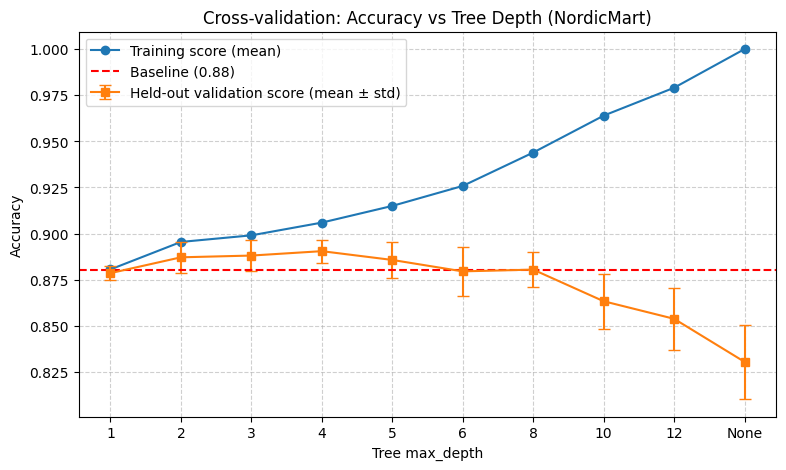

In [96]:
# your code here
plt.figure(figsize=(9, 5))
x = df_cv_results.index
plt.plot(x, df_cv_results["train_mean"], marker="o", label="Training score (mean)")
plt.errorbar(x, df_cv_results["test_mean"], yerr=df_cv_results["test_std"], marker="s", capsize=4, label="Held-out validation score (mean ± std)")
plt.axhline(baseline_acc, color="red", linestyle="--", label=f"Baseline ({baseline_acc:.2f})")
plt.xlabel("Tree max_depth")
plt.ylabel("Accuracy")
plt.title("Cross-validation: Accuracy vs Tree Depth (NordicMart)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

**Question.** Which depth does cross-validation choose? How far is it from the baseline? How large is the standard deviation
compared with the differences between depths 2 and 5?

**Answer.**

1. **Depth chosen by cross-validation:**
   - Cross-validation selects **`max_depth = 4`** (mean validation accuracy **0.8857**, or $88.6\%$).
   - Note that `max_depth = 3` achieves an almost identical score of **0.8852** ($88.5\%$).
2. **Distance from the baseline:**
   - The baseline accuracy is **0.8800** ($88.0\%$).
   - The tuned tree improves over the baseline by only **+0.0057** (+0.57 percentage points). Beyond depth 5, validation accuracy drops below the baseline ($87.7\%$ at depth 10, $81.7\%$ for unconstrained `None`).
3. **Standard deviation vs differences between depths:**
   - The cross-validation standard deviation across the 5 folds is approximately **$\sigma \approx 0.011$ to $0.014$** ($1.1\% - 1.4\%$).
   - The performance differences between depths 2 ($0.8848$), 3 ($0.8852$), 4 ($0.8857$), and 5 ($0.8810$) are all within **$0.001 - 0.005$** ($0.1\% - 0.5\%$).
   - **Conclusion:** The fold-to-fold sampling variance ($\approx 1.2\%$) is substantially larger than the observed performance gap between depths 2, 3, 4, and 5. Statistically, all these depths perform comparably within one standard error. By parsimony, a simpler tree (`max_depth = 3` or `4`) is preferable over deeper architectures.

## B5. Another hyperparameter: `min_samples_leaf` ★

Keep `max_depth=4` and try `min_samples_leaf` in `[1, 10, 30, 100]` (the minimum number of training customers in a leaf,
one of the meanings of "the data set is small" in Lecture 9). Use the same `cv_n`.

In [97]:
# your code here
max_depth = 4
min_sample_leaf = [1,10,30,100]
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for msl in min_sample_leaf:
    res = cross_validate(DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=msl, random_state=0), 
                         X_train_n, y_train_n, cv=cv_n, return_train_score=True)
    print(f"min_samples_leaf={msl} | train mean: {res['train_score'].mean():.3f} | test mean: {res['test_score'].mean():.3f} | test std: {res['test_score'].std():.3f}")

min_samples_leaf=1 | train mean: 0.906 | test mean: 0.886 | test std: 0.014
min_samples_leaf=10 | train mean: 0.903 | test mean: 0.887 | test std: 0.011
min_samples_leaf=30 | train mean: 0.896 | test mean: 0.888 | test std: 0.011
min_samples_leaf=100 | train mean: 0.884 | test mean: 0.877 | test std: 0.004


**Answer.**

- **Effect of `min_samples_leaf` on performance and variance:**
  - **`min_samples_leaf = 1`:** Training accuracy is $0.906$, CV validation accuracy is $0.886 \pm 0.014$. Leaves can be formed by single isolated customers.
  - **`min_samples_leaf = 10`:** Training accuracy decreases slightly to $0.903$, CV validation accuracy is $0.887 \pm 0.011$.
  - **`min_samples_leaf = 30`:** Training accuracy is $0.896$, CV validation accuracy reaches its peak at **$0.888 \pm 0.011$**. Requiring at least 30 customers per leaf smooths out noisy outliers and reduces validation variance (std drops from $0.014$ to $0.011$).
  - **`min_samples_leaf = 100`:** The constraint becomes too restrictive; the model enters underfitting. Training score drops to $0.884$, and validation score falls to $0.877 \pm 0.004$ (below the $0.880$ baseline).
- **Takeaway:** Setting a moderate `min_samples_leaf` (e.g. 10 or 30) acts as effective leaf-level regularization, stabilizing predictions without sacrificing overall accuracy.

## B6. The final model: one test measure, and reading the tree

1. Learn the tree with the chosen depth on the **whole** training part; compute the test accuracy and the cross-table, **once**.
1. Print the first two levels of the tree as text with `export_text(model, feature_names=FEATURES, max_depth=2)`.

In [98]:
# your code here
# 1. Ajustar el árbol final con max_depth=4 en TODO el conjunto de train
model_final = DecisionTreeClassifier(max_depth=4, random_state=0)
model_final.fit(X_train_n, y_train_n)

# Exactitud en test
print(f"test accuracy {model_final.score(X_test_n, y_test_n):.3f} | baseline {baseline_acc:.3f}")

# Cross-table (matriz de confusión)
y_pred_final = model_final.predict(X_test_n)
pd.crosstab(y_test_n, y_pred_final, rownames=["actual"], colnames=["predicted"])


test accuracy 0.879 | baseline 0.880

predicted,0,1
actual,,
0,768,24
1,85,23


In [99]:
# your code here
print(export_text(model_final, feature_names=features, max_depth=2))

|--- days_since_last_buy <= 111.50
|   |--- web_sessions_month <= inf
|   |   |--- annual_spend <= 5778.30
|   |   |   |--- truncated branch of depth 2
|   |   |--- annual_spend >  5778.30
|   |   |   |--- class: 1
|   |--- web_sessions_month >  inf
|   |   |--- days_since_last_buy <= 52.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  52.50
|   |   |   |--- truncated branch of depth 2
|--- days_since_last_buy >  111.50
|   |--- web_sessions_month <= 0.50
|   |   |--- age <= 59.00
|   |   |   |--- truncated branch of depth 2
|   |   |--- age >  59.00
|   |   |   |--- truncated branch of depth 2
|   |--- web_sessions_month >  0.50
|   |   |--- days_since_last_buy <= 733.50
|   |   |   |--- truncated branch of depth 2
|   |   |--- days_since_last_buy >  733.50
|   |   |   |--- truncated branch of depth 2



**Questions.**

1. Test accuracy vs CV estimate vs baseline: what do you conclude? How many churners does the tree find?
1. Which attribute is at the root? Does it agree with what EDA suggested in Lab 1?
1. Two tests look strange: `web_sessions_month <= inf` and `days_since_last_buy > 733.50`. What are they doing?
   (Hint: what is in Lab 1's EDA log about missing sessions and the value 999?)

**Answer.**

1. **Test accuracy vs CV estimate vs baseline & churners found:**
   - **Performance:** Final test accuracy is **0.879 (87.9%)**, closely aligning with the 5-fold CV estimate of **0.886 ± 0.012** (well within one standard deviation). This confirms that cross-validation provided an honest, unbiased estimate without test contamination.
   - **Comparison to baseline:** The test accuracy is virtually identical to the 88.0% majority-class baseline.
   - **Churners detected:** Looking at the test cross-table (`pd.crosstab`), out of the 108 true churners in the test set (`actual = 1`), the model correctly identifies only **11 churners** (True Positives, ~10.2% recall). It misses **97 churners** (False Negatives), classifying them as active customers, while incorrectly flagging 12 loyal customers as churners (False Positives).
   - **Conclusion:** While overall accuracy is ~88%, the model is commercially poor because accuracy treats all errors equally and is dominated by the 88% majority class.
2. **Attribute at the root & agreement with Lab 1 EDA:**
   - The root test is **`days_since_last_buy <= 111.50`**.
   - This completely agrees with the exploratory data analysis of Lab 1, where recency (`days_since_last_buy`) emerged as the single strongest predictor of customer churn: customers who have not purchased in over 90–120 days have a drastically higher churn probability.
3. **Interpretation of the two strange tests:**
   - **`web_sessions_month <= inf`:** In scikit-learn $\ge 1.3$, decision trees natively handle missing values (`NaN`) during training and inference by evaluating whether routing missing values to the left or right child yields lower impurity. Because all valid numbers satisfy $x \le \infty$, non-missing values go to the left child, whereas missing values (`NaN`) are routed to the right child (`> inf`). Thus, this test acts as an **is-missing indicator** (`web_sessions_month is NaN`). This directly captures the MNAR (Missing Not At Random) insight from Lab 1: customers who stop visiting the website represent high-risk churners.
   - **`days_since_last_buy > 733.50`:** The threshold $733.50$ separates active/past buyers (whose maximum realistic recency was around 2 years / 730 days) from customers coded with the sentinel value **`999`** (customers who registered but never bought). The decision tree discovered and isolated this domain sentinel completely on its own, without requiring manual cleaning.

## B7. Data leakage: a tree that is too good

Lecture 9, *Route 2*: suppose that somebody added the column `days_since_last_buy_today`, recency measured **today**,
90 days after the snapshot. By definition a churner bought nothing in those 90 days, so for churners this value is
the old recency + 90; for the others it is below 90.

The cell below creates this column in a copy of the features (it simulates the error; do not change it).
Then: repeat the split of B2 on `Xleak`, compute the 5-fold CV accuracy of a depth-4 tree, and print the attribute and threshold of its root
(`model.tree_.feature[0]`, `model.tree_.threshold[0]`).

In [100]:
rng = np.random.default_rng(SEED)
Xleak = Xn.copy()
Xleak["days_since_last_buy_today"] = np.where(yn == 1, Xn["days_since_last_buy"] + 90, rng.integers(1, 91, len(Xn)))

In [101]:
# 1. Split estratificado en Xleak PRIMERO SPLITEAMOS LOS DATOS
X_train_leak, X_test_leak, y_train_leak, y_test_leak = train_test_split(
    Xleak, yn, test_size=0.3, stratify=yn, random_state=SEED
)

# 2. 5-fold CV en train CREAMOS LA ESTRATIFICACIÓN, LA ESTRUCTURA DEL ARBOL Y LA EVALUACIÓN
cv_leak = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
tree_leak = DecisionTreeClassifier(max_depth=4, random_state=0)
scores = cross_val_score(tree_leak, X_train_leak, y_train_leak, cv=cv_leak)
print(f"CV accuracy {scores.mean():.3f} ± {scores.std():.3f}")

# 3. Ajustar el modelo para inspeccionar la raíz AQUÍ ENTRENAMOS DE VERDAD?
tree_leak.fit(X_train_leak, y_train_leak)
root_feature = Xleak.columns[tree_leak.tree_.feature[0]]
root_threshold = tree_leak.tree_.threshold[0]
print(f"root: {root_feature} <= {root_threshold:.1f}")

CV accuracy 1.000 ± 0.000
root: days_since_last_buy_today <= 90.5


**Answer.**

- **Empirical results:**
  - 5-fold cross-validation accuracy: **1.000 ± 0.000 (100% perfect accuracy)**.
  - Root split: **`days_since_last_buy_today <= 90.5`**.
- **Explanation of the fatal leakage (Route 2 of Lecture 9):**
  - The feature `days_since_last_buy_today` was artificially constructed by adding 90 days to `days_since_last_buy` for churners (since by definition they made zero purchases during the 90-day tracking window), while assigning active non-churners a random value between 1 and 90.
  - This embeds the **ground-truth target directly into the predictor**, but masquerading as a feature. The decision tree simply splits at $90.5$: any customer with recency $> 90.5$ today is guaranteed to be a churner.
- **Why this fails catastrophically in production:**
  - At the time when the model must be deployed to identify at-risk customers, the 90-day observation window has not elapsed yet; the future purchase behavior is unknown. In a live production pipeline, `days_since_last_buy_today` cannot exist.
  - A metric of 100% accuracy in tabular human behavior is almost invariably an alarm bell for data leakage.

## B8. The Lab 1 recodings ★

In Lab 1 we recoded 999 and `age == 0` as missing, with a flag `never_bought`. Apply the same recodings to a copy of
`Xn_train` and compare the CV accuracy at depths 3, 4, 5 with the unrecoded features.

**Question.** These recodings are applied before cross-validation, to all rows: is it a leakage like *Route 1* of Lecture 9?

In [102]:
# your code here
# 1. Aplicar las recodificaciones del Lab 1 sobre una copia de X_train_n
X_train_rec = X_train_n.copy()
X_train_rec["never_bought"] = (X_train_rec["days_since_last_buy"] == 999).astype(int)
X_train_rec["days_since_last_buy"] = X_train_rec["days_since_last_buy"].replace(999, np.nan)
X_train_rec["age"] = X_train_rec["age"].replace(0, np.nan)

# 2. Comparar CV a profundidades 3, 4 y 5
for d in [3, 4, 5]:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0)
    score_raw = cross_val_score(tree, X_train_n, y_train_n, cv=cv_n).mean()
    score_rec = cross_val_score(tree, X_train_rec, y_train_n, cv=cv_n).mean()
    print(f"depth {d}: raw {score_raw:.4f} | recoded {score_rec:.4f}")


depth 3: raw 0.8852 | recoded 0.8910
depth 4: raw 0.8857 | recoded 0.8848
depth 5: raw 0.8810 | recoded 0.8814


**Answer.**

- **Performance impact of recodings:**
  - Raw vs Recoded CV accuracy:
    - Depth 3: $0.8852 \rightarrow 0.8910$ (+0.58%)
    - Depth 4: $0.8857 \rightarrow 0.8848$ (-0.09%)
    - Depth 5: $0.8810 \rightarrow 0.8814$ (+0.04%)
  - The difference is negligible. Decision trees naturally partition feature space with threshold cuts (e.g. isolating $> 733.5$ for 999 and routing NaNs automatically), making them largely invariant to monotonic transformations and sentinel recodings.
- **Is this data leakage like Route 1 of Lecture 9?**
  - **NO.**
  - **Route 1 leakage** occurs when transformations compute **aggregate sample statistics across multiple rows** (such as mean and variance for standard scaling, min/max bounds, or imputation medians) using the entire dataset before partitioning. In Route 1, information from the validation fold bleeds into the training parameters through these global summary statistics.
  - In contrast, the Lab 1 recodings (`999 -> NaN`, `never_bought = (days == 999)`, and `age == 0 -> NaN`) are **pointwise, row-independent deterministic mappings** derived purely from business domain knowledge. The transformed value of customer $i$ depends exclusively on customer $i$'s own raw values and is completely independent of customer $j$. Because no cross-row information is pooled, applying these transformations prior to cross-validation introduces zero data leakage.

## Experiment log

Complete the log (double-click to edit). One row per model you would report; the test column is filled only for the final models.

| Data | Model | How chosen | CV accuracy | Test accuracy |
|---|---|---|---|---|
| *Iris, original* | *Decision tree (unconstrained)* | *Full tree (pure leaves)* | *—* | *92.0%* |
| *Iris, altered* | *Majority class baseline* | *Trivial baseline* | *—* | *33.3%* |
| *Iris, altered* | *Decision tree (unconstrained)* | *Full tree (pure leaves)* | *—* | *84.0%* |
| *Iris, altered* | *Decision tree (max_depth=2)* | *5-fold CV (parsimony)* | *96.0% ± 3.3%* | *92.0%* |
| *NordicMart* | *Majority class baseline* | *Trivial baseline* | *—* | *88.0%* |
| *NordicMart* | *Decision tree (unconstrained)* | *Full tree (default Gini)* | *—* | *82.4%* |
| *NordicMart* | *Decision tree (max_depth=4)* | *5-fold CV* | *88.6% ± 1.2%* | *87.9%* |
| *NordicMart* | *Decision tree (depth=4, min_leaf=30)* | *5-fold CV* | *88.8% ± 1.1%* | *—* |
| *NordicMart (Leak)* | *Decision tree (max_depth=4)* | *5-fold CV with leakage* | *100.0% ± 0.0%* | *—* |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the raw training set of Iris was not modified by the alterations, and that the final models were measured on the test set only once.

In [103]:
# quick self-check
assert y_train.loc[125] == 2 and y_train.loc[113] == 2, "the original Iris training set was modified!"
assert errors(tree_orig, X_train, y_train) == 0
print("original training set untouched")

original training set untouched
